# Wellness Tourism Package Purchase Prediction

This project predicts whether a customer is likely to purchase the Wellness Tourism Package using historical customer data from Visit with Us.

The dataset contains a binary target variable, `ProdTaken` (1 = purchased, 0 = not purchased). Because the dataset does not separately identify Wellness Tourism Package purchases, this project assumes that `ProdTaken` represents Wellness Tourism Package purchase status.

The course team has confirmed that this interpretation is acceptable when clearly documented and consistently applied.

This assumption is a limitation because the dataset does not independently verify the package type.

Decision Tree, Random Forest, and Gradient Boosting models are compared using cross-validation. The selected model is evaluated on a held-out test set and used in a Streamlit prediction application.

**Repository:** [Tourism-Package-Predictions](https://github.com/Maverick-Manoj/Tourism-Package-Predictions)

In [1]:
from pathlib import Path
import os
import subprocess
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

# Find the project folder when running from the repository or notebooks folder.
locations = [Path.cwd(), Path.cwd().parent]
ROOT = next(
    (folder for folder in locations if (folder / "data" / "tourism.csv").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/tourism.csv. Open this notebook from the cloned "
        "Tourism-Package-Predictions repository."
    )

os.chdir(ROOT)
print(f"Project: {ROOT.name}")
print(f"Python: {sys.version.split()[0]}")
print(f"Pandas: {pd.__version__}")

Project: tourism-package-prediction
Python: 3.13.5
Pandas: 2.2.3


## 1. Inspect and validate the dataset

I begin by checking the expected columns, the binary purchase target, unique customer IDs, and missing values. The same checks are implemented in `src/validate_data.py` so that the GitHub workflow can run them without the notebook.

In [2]:
from src.validate_data import validate_file

validation = validate_file(ROOT / "data" / "tourism.csv")
raw = pd.read_csv(ROOT / "data" / "tourism.csv")

print(f"Rows: {len(raw):,}")
print(f"Columns: {len(raw.columns)}")
print(f"Missing values: {raw.isna().sum().sum():,}")
display(raw.head())
display(raw.isna().sum().rename("missing_values").to_frame())

Data validation summary
{
  "dataset": "data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "missing_cells": 0,
  "duplicate_customer_ids": 0,
  "target_distribution": {
    "0": 3331,
    "1": 797
  },
  "purchase_rate": 0.193072,
  "unrecognized_columns": [],
  "validation_status": "PASS"
}
Rows: 4,128
Columns: 21
Missing values: 0


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


,missing_values
Unnamed: 0,0
CustomerID,0
ProdTaken,0
Age,0
TypeofContact,0
CityTier,0
DurationOfPitch,0
Occupation,0
Gender,0
NumberOfPersonVisiting,0


## 2. Examine purchase outcomes and categorical values

Most customers have `ProdTaken = 0`, indicating no purchase under the project's Wellness Tourism Package assumption. Because purchases are less frequent than non-purchases, accuracy alone may be misleading. Model comparison therefore emphasizes average precision and also reports ROC-AUC.

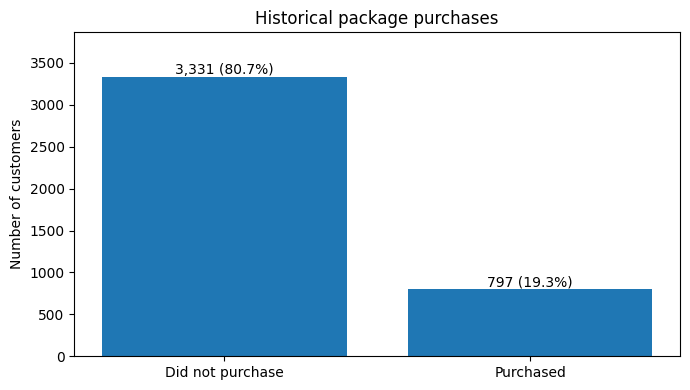

Gender values: ['Fe Male', 'Female', 'Male']
Marital status values: ['Divorced', 'Married', 'Single', 'Unmarried']
Duplicate rows: 0
Majority-class accuracy: 80.7%


In [3]:
purchase_counts = raw["ProdTaken"].value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Did not purchase", "Purchased"]
bars = ax.bar(labels, purchase_counts.values)

for bar, count in zip(bars, purchase_counts.values):
    ax.annotate(
        f"{count:,} ({count / len(raw):.1%})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )

ax.set_ylim(0, purchase_counts.max() * 1.16)
ax.set_ylabel("Number of customers")
ax.set_title("Historical package purchases")
plt.tight_layout()
plt.show()

print("Gender values:", sorted(raw["Gender"].dropna().unique()))
print("Marital status values:", sorted(raw["MaritalStatus"].dropna().unique()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Majority-class accuracy:", f"{purchase_counts[0] / len(raw):.1%}")

### Variables available at prediction time

The model uses customer information that could be available before a sales call.

I removed customer IDs, the extra index column, and fields related to the sales interaction. These would not be available when making a prediction before contacting the customer.

The cleaning function also changes `Fe Male` to `Female` and `Unmarried` to `Single`. Before using the model in a real campaign, I would confirm that the remaining fields are available.

In [4]:
from src.common import DROP_COLUMNS, FEATURE_COLUMNS, clean_data

cleaned = clean_data(raw)
print("Model features:", len(FEATURE_COLUMNS))
print("Excluded columns:", ", ".join(DROP_COLUMNS))
print("Prepared data shape:", cleaned.shape)
display(cleaned.head())

Model features: 13
Excluded columns: Unnamed: 0, CustomerID, TypeofContact, DurationOfPitch, NumberOfFollowups, ProductPitched, PitchSatisfactionScore
Prepared data shape: (4128, 14)


,Age,CityTier,Occupation,Gender,NumberOfPersonVisiting,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome,ProdTaken
0,41.0,3,Salaried,Female,3,3.0,Single,1.0,1,1,0.0,Manager,20993.0,1
1,49.0,1,Salaried,Male,3,4.0,Divorced,2.0,0,1,2.0,Manager,20130.0,0
2,37.0,1,Free Lancer,Male,3,3.0,Single,7.0,1,0,0.0,Executive,17090.0,1
3,33.0,1,Salaried,Female,2,3.0,Divorced,2.0,1,1,1.0,Executive,17909.0,0
4,32.0,1,Salaried,Male,3,3.0,Single,1.0,0,1,1.0,Executive,18068.0,0


## 3. Prepare the training and test sets

An 80/20 stratified split preserves roughly the same purchase rate in each subset. The preparation script writes `train.csv` and `test.csv` to `build/`. In GitHub Actions, these files are passed from the preparation job to the training job as an artifact.

In [5]:
from src.prepare_data import prepare

train, test, split_summary = prepare(
    ROOT / "data" / "tourism.csv",
    ROOT / "build",
    test_size=0.20,
    seed=42,
)

sample_summary = []

for name, dataset in [("Training", train), ("Test", test)]:
    sample_summary.append({
        "sample": name,
        "customers": len(dataset),
        "purchases": int(dataset["ProdTaken"].sum()),
        "purchase_rate": dataset["ProdTaken"].mean()
    })

display(pd.DataFrame(sample_summary))

Data validation summary
{
  "dataset": "data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "missing_cells": 0,
  "duplicate_customer_ids": 0,
  "target_distribution": {
    "0": 3331,
    "1": 797
  },
  "purchase_rate": 0.193072,
  "unrecognized_columns": [],
  "validation_status": "PASS"
}


Data preparation summary
{
  "train_rows": 3302,
  "test_rows": 826,
  "train_positive_rate": 0.193216,
  "test_positive_rate": 0.192494,
  "feature_columns": [
    "Age",
    "CityTier",
    "Occupation",
    "Gender",
    "NumberOfPersonVisiting",
    "PreferredPropertyStar",
    "MaritalStatus",
    "NumberOfTrips",
    "Passport",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "Designation",
    "MonthlyIncome"
  ],
  "train_file": "build/train.csv",
  "test_file": "build/test.csv",
  "test_size": 0.2,
  "random_state": 42
}


,sample,customers,purchases,purchase_rate
0,Training,3302,638,0.193216
1,Test,826,159,0.192494


## 4. Compare classification models

The training pipeline compares six classifiers: Decision Tree, Bagging, Random Forest, AdaBoost, Gradient Boosting, and XGBoost (when the optional dependency is installed).

Each classifier is tuned with 3-fold stratified cross-validation on the training split. Preprocessing for missing and categorical values is fitted inside the pipeline. Models are ranked by mean cross-validated average precision, which is appropriate for an imbalanced purchase target.

The winning classifier's decision threshold is then selected by maximizing F1 on out-of-fold training predictions. The held-out test set is reserved for evaluation, not model or threshold selection. The training script records experiment results in `reports/experiments.json` and MLflow.

In [6]:
from src.train_model import experiment

best_model, metrics, trials = experiment(
    ROOT / "build" / "train.csv",
    ROOT / "build" / "test.csv",
    ROOT / "models",
    ROOT / "reports",
    ROOT / "mlruns",
)

print("Selected model:", metrics["selected_algorithm"])
print("Cross-validated average precision:", f"{metrics['selected_cv_pr_auc']:.3f}")
print("Experiment records:", len(trials))

DecisionTree: mean CV average precision = 0.5530


RandomForest: mean CV average precision = 0.7001


GradientBoosting: mean CV average precision = 0.6059
Selected model: RandomForest
Test ROC-AUC: 0.915
Test average precision: 0.718
              precision    recall  f1-score   support

           0       0.88      0.98      0.93       667
           1       0.85      0.42      0.56       159

    accuracy                           0.87       826
   macro avg       0.86      0.70      0.74       826
weighted avg       0.87      0.87      0.85       826

Selected model: RandomForest
Cross-validated average precision: 0.700
Experiment records: 12


In [ ]:
model_comparison = pd.DataFrame(metrics["cv_results_by_model"])
display(model_comparison)

fig, ax = plt.subplots(figsize=(9, 4))
ordered = model_comparison.sort_values("best_cv_pr_auc")
ax.barh(ordered["algorithm"], ordered["best_cv_pr_auc"])
ax.set_xlim(0, 1)
ax.set_xlabel("Mean cross-validated average precision")
ax.set_title("Classifier comparison")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(trials)
    .sort_values("cv_mean_pr_auc", ascending=False)
    .head(10)
)

## 5. Evaluate on the test set

The selected model is evaluated once on the held-out 20% test split. Average precision and ROC-AUC measure ranking quality independently of a decision cutoff.

I report classification metrics at both the conventional 0.50 reference cutoff and the model-selected cutoff. The latter is chosen by maximizing F1 on out-of-fold predictions from the training data only (0.37 in the verified GitHub run). The test set does not determine this cutoff. Campaign costs and outreach capacity may justify a different operational threshold.

In [ ]:
from src.evaluate_model import evaluate

saved_model_metrics = evaluate(
    ROOT / "models" / "best_model.joblib",
    ROOT / "build" / "test.csv",
)

metric_labels = {
    "Cross-validation average precision": "selected_cv_pr_auc",
    "Test average precision": "holdout_average_precision",
    "Test ROC-AUC": "holdout_roc_auc",
    "Precision at 0.50": "holdout_precision_at_0_5",
    "Recall at 0.50": "holdout_recall_at_0_5",
    "F1 at 0.50": "holdout_f1_at_0_5",
    "Accuracy at 0.50": "holdout_accuracy_at_0_5",
    "Selected threshold": "tuned_threshold",
    "Precision at selected threshold": "holdout_precision_at_tuned",
    "Recall at selected threshold": "holdout_recall_at_tuned",
    "F1 at selected threshold": "holdout_f1_at_tuned",
    "Accuracy at selected threshold": "holdout_accuracy_at_tuned",
}
display(pd.DataFrame([
    {"metric": label, "value": metrics[key]}
    for label, key in metric_labels.items()
]))
print("Threshold selection:", metrics["threshold_selection"])

In [ ]:
X_test = test[FEATURE_COLUMNS]
y_test = test["ProdTaken"].astype(int)
probabilities = best_model.predict_proba(X_test)[:, 1]
selected_threshold = float(metrics["tuned_threshold"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (probabilities >= selected_threshold).astype(int),
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title(f"Confusion matrix (threshold = {selected_threshold:.2f})")

precision, recall, _ = precision_recall_curve(y_test, probabilities)
axes[1].plot(recall, precision, label="Trained model")
axes[1].axhline(y_test.mean(), linestyle="--", label="Class prevalence")
axes[1].set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision-recall curve",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Does the model help rank prospective customers?

Under the documented target assumption, higher model scores identify customers with a greater estimated likelihood of purchasing the Wellness Tourism Package. Ranking lift measures how effectively the model concentrates historical purchases among higher-scoring customers. It does not establish that marketing contact causes additional purchases.

The chart shows historical purchase rates for each score decile.

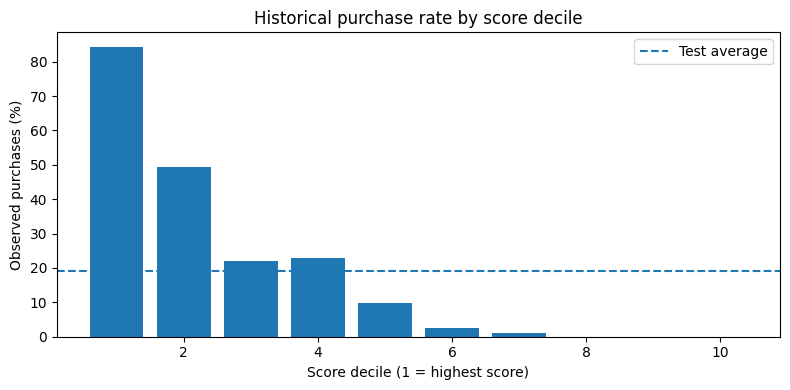

The top 20% of scores had a purchase rate of 66.9%, compared with 19.2% overall. Ranking lift: 3.47x.


In [10]:
ranking = pd.DataFrame({
    "purchase": y_test.to_numpy(),
    "score": probabilities,
}).sort_values("score", ascending=False).reset_index(drop=True)

ranking["decile"] = (
    np.minimum(10 * np.arange(len(ranking)) // len(ranking), 9) + 1
)
by_decile = ranking.groupby("decile", as_index=False).agg(
    purchase_rate=("purchase", "mean"),
    customers=("purchase", "size"),
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decile["decile"], 100 * by_decile["purchase_rate"])
ax.axhline(100 * y_test.mean(), linestyle="--", label="Test average")
ax.set(
    xlabel="Score decile (1 = highest score)",
    ylabel="Observed purchases (%)",
    title="Historical purchase rate by score decile",
)
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"The top 20% of scores had a purchase rate of "
    f"{metrics['top_20pct_positive_rate']:.1%}, compared with "
    f"{metrics['test_positive_rate']:.1%} overall. "
    f"Ranking lift: {metrics['top_20pct_lift']:.2f}x."
)

## 7. Review feature importance

Bagging does not expose a single `feature_importances_` attribute for the complete ensemble. Instead, I use **permutation importance** on the fitted preprocessing-and-classification pipeline: each original input column is shuffled in the held-out test data and the reduction in average precision is measured.

This is a descriptive, model-specific measure of reliance on each feature, **not a causal effect**. These test-set importance results are not used for model or threshold selection.

In [ ]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)
feature_importance = pd.Series(
    importance.importances_mean,
    index=X_test.columns,
).sort_values(ascending=False)

print("Selected model:", metrics["selected_algorithm"])
display(feature_importance.head(12).to_frame("mean AP decrease"))

fig, ax = plt.subplots(figsize=(8, 4))
feature_importance.head(12).sort_values().plot.barh(ax=ax)
ax.set_xlabel("Decrease in average precision after permutation")
ax.set_title("Permutation importance (held-out test set)")
plt.tight_layout()
plt.show()

## 8. Streamlit model interface

The Streamlit app in `app.py` builds a one-row DataFrame from the customer form and calls `predict_proba` on the saved preprocessing and classification pipeline. The model and metadata are loaded from `models/`.

The interface can be deployed from this repository using Streamlit Community Cloud. Hugging Face Spaces is an optional alternative deployment platform. Additional deployment configuration would be required to use it for this project.

**Deployment clarification from Academic Support:** Learners may deploy the application using either Streamlit Community Cloud or Hugging Face Spaces. Both options are accepted and graded equally. Hugging Face deployment is not mandatory. Academic Support recommends Streamlit Community Cloud because it is free for learners.

This project uses Streamlit Community Cloud for deployment.

In [12]:
required_files = {
    "Customer dataset": ROOT / "data" / "tourism.csv",
    "Streamlit app": ROOT / "app.py",
    "App dependencies": ROOT / "requirements.txt",
    "Trained model": ROOT / "models" / "best_model.joblib",
    "Model metadata": ROOT / "models" / "model_metadata.json",
    "Experiment results": ROOT / "reports" / "experiments.json",
    "GitHub Actions workflow": ROOT / ".github" / "workflows" / "pipeline.yml",
}

for label, path in required_files.items():
    print(f"{label}: {'Found' if path.is_file() else 'Missing'}")

assert all(path.is_file() for path in required_files.values())

Customer dataset: Found
Streamlit app: Found
App dependencies: Found
Trained model: Found
Model metadata: Found
Experiment results: Found
GitHub Actions workflow: Found


## 9. Automated GitHub Actions pipeline

The GitHub Actions workflow runs four jobs in order: validate, prepare, train, and publish. Train and test files are passed between jobs as artifacts. The final job commits updated model and report files when needed.

The next cell checks the workflow definition. I verify completed runs separately on the GitHub Actions page.

In [13]:
import yaml

workflow_path = ROOT / ".github" / "workflows" / "pipeline.yml"
workflow = yaml.safe_load(workflow_path.read_text(encoding="utf-8"))

jobs = pd.DataFrame([
    {
        "job": name,
        "depends_on": job.get("needs", "None"),
        "steps": len(job["steps"]),
    }
    for name, job in workflow["jobs"].items()
])
display(jobs)
assert set(workflow["jobs"]) == {"validate", "prepare", "train", "publish"}

,job,depends_on,steps
0,validate,None,6
1,prepare,validate,5
2,train,prepare,8
3,publish,train,3


## 10. Test the project files

The automated test suite contains ten tests covering schema validation, data cleaning, serialized predictions, candidate classifiers, and training-only threshold selection. The independent evaluation script loads the saved model and scores the held-out test split.

The GitHub Actions validation job passed all 10 tests in the verified November 7, 2026 run.

In [14]:
tests = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    capture_output=True,
    text=True,
)
print(tests.stdout)
if tests.returncode:
    print(tests.stderr)
assert tests.returncode == 0

print("Scored test observations:", saved_model_metrics["num_scores"])

......                                                                   [100%]
6 passed in 0.89s

Scored test observations: 826


## 11. Findings and Business Recommendations

Six candidate classifiers were compared using stratified cross-validation, and the model with the strongest mean average precision was selected. **Bagging** won in the verified GitHub run. On the held-out test split it achieved average precision of **0.818**, ROC-AUC of **0.942**, and top-20% ranking lift of **3.82×**. At the training-selected **0.37** cutoff, test precision was **75.3%** and recall was **74.8%**. The notebook's executed values should be used if a subsequent retraining run differs.

Under the documented assumption that `ProdTaken` identifies **Wellness Tourism Package** purchases, the model can help prioritize customers for a controlled marketing pilot. The source data does not independently establish the package type, so this remains an explicit limitation.

**Business recommendations:**

1. Pilot outreach to higher-scoring customers and measure actual conversions against a comparison group.
2. Start with the training-selected cutoff, then adjust for campaign costs, contact capacity, and precision-recall tradeoffs.
3. Monitor calibration, conversion, and predictive performance on new customers; retrain when performance deteriorates.
4. Verify the historical package label before drawing operational conclusions specifically about Wellness package demand.

Historical predictive associations do not establish that an outreach intervention causes additional purchases.

In [ ]:
winner = max(
    metrics["cv_results_by_model"],
    key=lambda model: model["best_cv_pr_auc"],
)
print(f"Customers analyzed: {len(raw):,}")
print(f"Historical purchase rate: {raw['ProdTaken'].mean():.1%}")
print(f"Best model: {winner['algorithm']}")
print(f"Best cross-validation average precision: {winner['best_cv_pr_auc']:.3f}")
print(f"Test ROC-AUC: {metrics['holdout_roc_auc']:.3f}")
print(f"Test average precision: {metrics['holdout_average_precision']:.3f}")
print(f"Top 20% ranking lift: {metrics['top_20pct_lift']:.2f}x")
print(f"Training-selected threshold: {metrics['tuned_threshold']:.2f}")
print(f"Test precision at selected threshold: {metrics['holdout_precision_at_tuned']:.3f}")
print(f"Test recall at selected threshold: {metrics['holdout_recall_at_tuned']:.3f}")
print(f"Test F1 at selected threshold: {metrics['holdout_f1_at_tuned']:.3f}")

## Project links and deployment evidence

- [GitHub repository](https://github.com/Maverick-Manoj/Tourism-Package-Predictions)
- [Successful GitHub Actions workflow](https://github.com/Maverick-Manoj/Tourism-Package-Predictions/actions/runs/42380413257)
- [Live Streamlit application](https://tourism-package-predictions-lgjwmxlyarcygv33rfglg6.streamlit.app/)
- Hugging Face Spaces: optional — not deployed

**Academic Support clarification:** Streamlit Community Cloud deployment satisfies the deployment requirement. Hugging Face Spaces is optional and is not required for grading.

### Repository structure

![GitHub repository structure](https://raw.githubusercontent.com/Maverick-Manoj/Tourism-Package-Predictions/main/docs/screenshots/01_repo_structure.png)

### Successful workflow and generated artifacts

![GitHub Actions successful pipeline](https://raw.githubusercontent.com/Maverick-Manoj/Tourism-Package-Predictions/main/docs/screenshots/02_workflow_run.png)

### Live prediction interface

![Streamlit prediction and performance](https://raw.githubusercontent.com/Maverick-Manoj/Tourism-Package-Predictions/main/docs/screenshots/03_streamlit_app.png)